# EDA

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

## Librerias

In [1]:
import os
import re
import time
import warnings
from getpass import getpass

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns

#%matplotlib qt

## Analisis archivo "SC-subjects.xls"

El archivo *SC-subjects.xls* pertenece a la documentación de Sleep-EDF Database Expanded y contiene información de referencia sobre los sujetos incluidos en el subconjunto SC. Se utiliza para consultar datos de los participantes y contextualizar las grabaciones polisomnográficas asociadas a cada sujeto. Por lo cual es necesario de revisar.

Los 153 archivos **SC (SC = Sleep Cassette, o «casete de sueño»)** se obtuvieron en un estudio realizado entre 1987 y 1991 sobre los efectos de la edad en el sueño de personas caucásicas sanas de entre 25 y 101 años, sin medicación relacionada con el sueño. Se registraron dos PSG (polisomnografías) de aproximadamente 20 horas cada una durante dos períodos consecutivos de día y noche en los domicilios de los participantes. Los participantes continuaron con sus actividades habituales, pero llevaban un grabador de casetes modificado, similar a un Walkman.

Los archivos tienen nombres con el formato **SC4ssNEO-PSG.edf**, donde:
- ss corresponde al número del participante
- N a la noche.

*Nota*: Se perdieron las primeras noches de los participantes 36 y 52, así como la segunda noche del participante 13, debido a un fallo del casete o del disco láser.

Las señales de EOG y EEG se muestrearon a 100 Hz cada una. La señal de EMG submentoniana fue filtrada electrónicamente mediante un filtro pasaaltos, rectificada y posteriormente filtrada mediante un filtro pasabajos. Después de este procesamiento, la envolvente de EMG resultante, expresada en µV RMS (valor cuadrático medio), se muestreó a 1 Hz. El flujo de aire oronasal, la temperatura corporal rectal y el marcador de eventos también se muestrearon a 1 Hz.

---
*El siguiente texto fue traducido y adaptado de la información disponible en [Sleep-EDF Database Expanded](https://physionet.org/content/sleep-edfx/1.0.0/#files-panel).*

In [2]:
sc_subjects = pd.read_excel("../data/sleep-edfx/SC-subjects.xls")
sc_subjects.head()

,subject,night,age,sex (F=1),LightsOff
0,0,1,33,1,00:38:00
1,0,2,33,1,21:57:00
2,1,1,33,1,22:44:00
3,1,2,33,1,22:15:00
4,2,1,26,1,22:50:00


In [3]:
print(f'Columnas: {sc_subjects.columns}')
print('*----'*20)
print(f'Tamaño del dataset: {sc_subjects.shape}')
print('*----'*20)
print(f"Filas duplicadas: {sc_subjects.duplicated().sum()}")

Columnas: Index(['subject', 'night', 'age', 'sex (F=1)', 'LightsOff'], dtype='object')
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Tamaño del dataset: (153, 5)
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Filas duplicadas: 0


In [4]:
print(f"Sujetos duplicados: {sc_subjects['subject'].duplicated().sum() if 'subject' in sc_subjects.columns else 'revisar nombre de columna'}")

Sujetos duplicados: 75


In [5]:
print(sc_subjects.groupby('subject')['night'].count().value_counts())

night
2    75
1     3
Name: count, dtype: int64


Se evidencia que efectivamente son 3 sujetos que no tienen 2 noches de registro, como lo indica la descripción del dataset. 

In [6]:
sc_subjects.describe()

,subject,night,age,sex (F=1)
count,153.000000,153.000000,153.000000,153.000000
mean,39.470588,1.503268,58.986928,1.464052
std,23.694342,0.501631,22.118100,0.500344
min,0.000000,1.000000,25.000000,1.000000
25%,19.000000,1.000000,34.000000,1.000000
50%,40.000000,2.000000,57.000000,1.000000
75%,59.000000,2.000000,73.000000,2.000000
max,82.000000,2.000000,101.000000,2.000000


Distribución de la variable 'sex' 

sex (F=1)
1    82
2    71
Name: count, dtype: int64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
sex (F=1)
1    53.594771
2    46.405229
Name: proportion, dtype: float64
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----



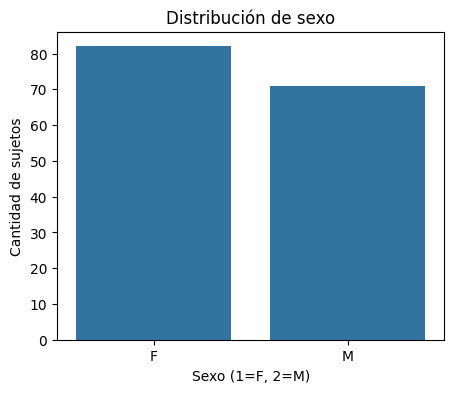

In [7]:
# Balance de la clase 'sex' (F=1)
print('Distribución de la variable \'sex\' \n')
print(sc_subjects['sex (F=1)'].value_counts())
print('*----'*15)
print(sc_subjects['sex (F=1)'].value_counts(normalize=True) * 100)
print('*----'*15 + "\n")

plt.figure(figsize=(5, 4))
sns.countplot(x='sex (F=1)', data=sc_subjects)
plt.xlabel("Sexo (1=F, 2=M)")
plt.ylabel("Cantidad de sujetos")
plt.title("Distribución de sexo")
plt.xticks(ticks=[0, 1], labels=['F', 'M'])
plt.show()

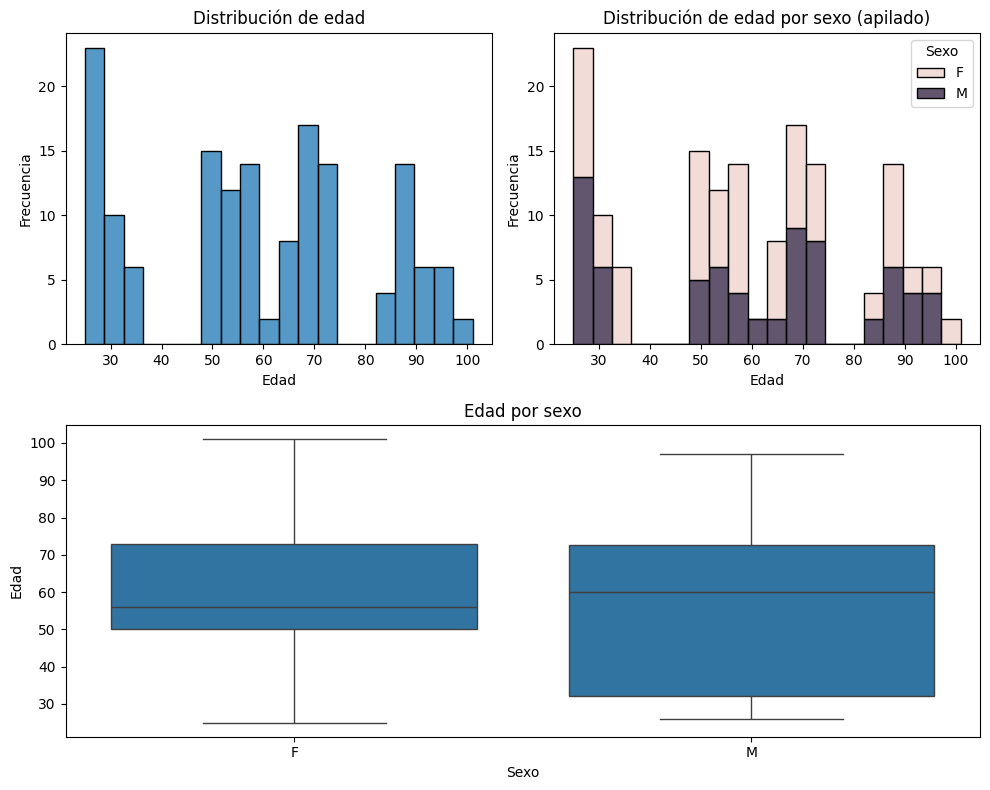

In [8]:
fig, axes = plt.subplot_mosaic(
    [['hist', 'hist_stack'],
     ['box', 'box']],
    figsize=(10, 8)
)

# Histograma simple
sns.histplot(sc_subjects['age'], bins=20, ax=axes['hist'])
axes['hist'].set_xlabel("Edad")
axes['hist'].set_ylabel("Frecuencia")
axes['hist'].set_title("Distribución de edad")

# Histograma apilado por sexo
sns.histplot(
    data=sc_subjects,
    x='age',
    hue='sex (F=1)',
    multiple='stack',
    bins=20,
    ax=axes['hist_stack']
)
axes['hist_stack'].set_xlabel("Edad")
axes['hist_stack'].set_ylabel("Frecuencia")
axes['hist_stack'].set_title("Distribución de edad por sexo (apilado)")

# Boxplot de edad por cada genero
legend = axes['hist_stack'].get_legend()
legend.set_title("Sexo")
for text, label in zip(legend.get_texts(), ['F', 'M']):
    text.set_text(label)

sns.boxplot(x='sex (F=1)', y='age', data=sc_subjects, ax=axes['box'])
axes['box'].set_xlabel("Sexo")
axes['box'].set_ylabel("Edad")
axes['box'].set_title("Edad por sexo")
axes['box'].set_xticks([0, 1])
axes['box'].set_xticklabels(['F', 'M'])

plt.tight_layout()
plt.show()

In [9]:
sc_subjects.groupby('sex (F=1)')['age'].describe()

,count,mean,std,min,25%,50%,75%,max
sex (F=1),,,,,,,,
1,82.0,58.536585,21.475335,25.0,50.0,56.0,73.0,101.0
2,71.0,59.507042,22.980658,26.0,32.0,60.0,72.5,97.0


## Analisis de la estructura de un archivo de Polisomnografía (PSG)

In [10]:
sc_files = [
    f for f in os.listdir("../data/sleep-edfx/sleep-cassette")
    if f.endswith("-PSG.edf")
]

print(f"Total archivos SC-PSG: {len(sc_files)}")
print(f"Ejemplos de PSG: {sc_files[:5]}")
print('*----'*25)

sc_files = [
    f for f in os.listdir("../data/sleep-edfx/sleep-cassette")
    if f.endswith("-Hypnogram.edf")
]

print(f"Total archivos SC-Hypnogram: {len(sc_files)}")
print(f"Ejemplos de Hypnogram: {sc_files[:5]}")

Total archivos SC-PSG: 153
Ejemplos de PSG: ['SC4201E0-PSG.edf', 'SC4171E0-PSG.edf', 'SC4272F0-PSG.edf', 'SC4421E0-PSG.edf', 'SC4751E0-PSG.edf']
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Total archivos SC-Hypnogram: 153
Ejemplos de Hypnogram: ['SC4411EJ-Hypnogram.edf', 'SC4611EG-Hypnogram.edf', 'SC4141EU-Hypnogram.edf', 'SC4662EJ-Hypnogram.edf', 'SC4401EC-Hypnogram.edf']


Se valida la estructura de uno de los archivos de polisomnografía con uno de los pacientes.

In [11]:
psg_path = "../data/sleep-edfx/sleep-cassette/"
psg_file = "SC4001E0-PSG.edf"

print("Ejemplo " + psg_file + "\n")
raw = mne.io.read_raw_edf(psg_path + psg_file, preload=True)

Ejemplo SC4001E0-PSG.edf

Extracting EDF parameters from ../data/sleep-edfx/sleep-cassette/SC4001E0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 7949999  =      0.000 ... 79499.990 secs...


/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/2528577683.py:5: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path + psg_file, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/2528577683.py:5: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path + psg_file, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/2528577683.py:5: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path + psg_file, preload=True)


In [12]:
print(raw.info)

<Info | 8 non-empty values
 bads: []
 ch_names: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal, Resp oro-nasal, EMG ...
 chs: 7 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 50.0 Hz
 meas_date: 1989-04-24 16:13:00 UTC
 nchan: 7
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>
>


In [13]:
print("Canales disponibles en el archivo " + psg_file + ":")
print(raw.ch_names)

Canales disponibles en el archivo SC4001E0-PSG.edf:
['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'Resp oro-nasal', 'EMG submental', 'Temp rectal', 'Event marker']


De acuerdo a lo descrito en la propuesta de proyecto de grado, solo se van a mantener los canales EEG (2 canales), EOG y EMG

In [14]:
channels_to_use = ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'EMG submental']

In [15]:
print("Unidades originales en el EDF:", raw._orig_units)
print("Unidad interna de MNE (FIFF):", {ch["ch_name"]: ch["unit"] for ch in raw.info["chs"]})
print(raw.get_data(picks="EEG Fpz-Cz", units="uV")[0, :5])  # valores en voltios (~1e-5)

Unidades originales en el EDF: {'EEG Fpz-Cz': 'µV', 'EEG Pz-Oz': 'µV', 'EOG horizontal': 'µV', 'Resp oro-nasal': 'n/a', 'EMG submental': 'µV', 'Temp rectal': 'n/a', 'Event marker': 'n/a'}
Unidad interna de MNE (FIFF): {'EEG Fpz-Cz': 107 (FIFF_UNIT_V), 'EEG Pz-Oz': 107 (FIFF_UNIT_V), 'EOG horizontal': 107 (FIFF_UNIT_V), 'Resp oro-nasal': 107 (FIFF_UNIT_V), 'EMG submental': 107 (FIFF_UNIT_V), 'Temp rectal': 107 (FIFF_UNIT_V), 'Event marker': 107 (FIFF_UNIT_V)}
[ 5.01684982 -2.57875458  1.35970696 -2.39120879 -5.2043956 ]


La anterior celda nos permite concluir lo siguiente:
- En el archivo EDF, los canales que se usanrán (EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal y EMG submental) están guardados en µV.
- Dentro de MNE, todos los canales pasan a voltios (FIFF_UNIT_V). Por eso get_data() devuelve valores del orden de 1e-6, por ejemplo el 5.02e-06 de la salida equivale a unos 5 µV en EEG Fpz-Cz, un valor normal. Sin embargo se puede usar el parametro units indicando la escala original de la señal. 

## Analisis de la estructura de un archivo de etiqueta del hipnograma

In [16]:
psg_path = "../data/sleep-edfx/sleep-cassette/"
hypnogram_file = "SC4001EC-Hypnogram.edf"

annot = mne.read_annotations(psg_path + hypnogram_file)
print("Ejemplo " + hypnogram_file + "\n")
print(f"Cantidad de anotaciones para un ejemplo: {len(annot.description)}")
print(f"Ejemplo: {annot.description[:5]}")
print('*----'*20)
print(f"Duración para la anotación del ejemplo: {len(annot.duration)}")
print(f"Ejemplo: {annot.duration[:5]}")

Ejemplo SC4001EC-Hypnogram.edf

Cantidad de anotaciones para un ejemplo: 154
Ejemplo: ['Sleep stage W' 'Sleep stage 1' 'Sleep stage 2' 'Sleep stage 3'
 'Sleep stage 2']
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Duración para la anotación del ejemplo: 154
Ejemplo: [3.063e+04 1.200e+02 3.900e+02 3.000e+01 3.000e+01]


In [17]:
df_annot = pd.DataFrame({
    "anotacion": annot.description,
    "duracion_seg": annot.duration
})

df_annot["duracion_min"] = df_annot["duracion_seg"] / 60

display(df_annot.head())

,anotacion,duracion_seg,duracion_min
0,Sleep stage W,30630.0,510.5
1,Sleep stage 1,120.0,2.0
2,Sleep stage 2,390.0,6.5
3,Sleep stage 3,30.0,0.5
4,Sleep stage 2,30.0,0.5


## Ejemplos de Hipnogramas

Using matplotlib as 2D backend.


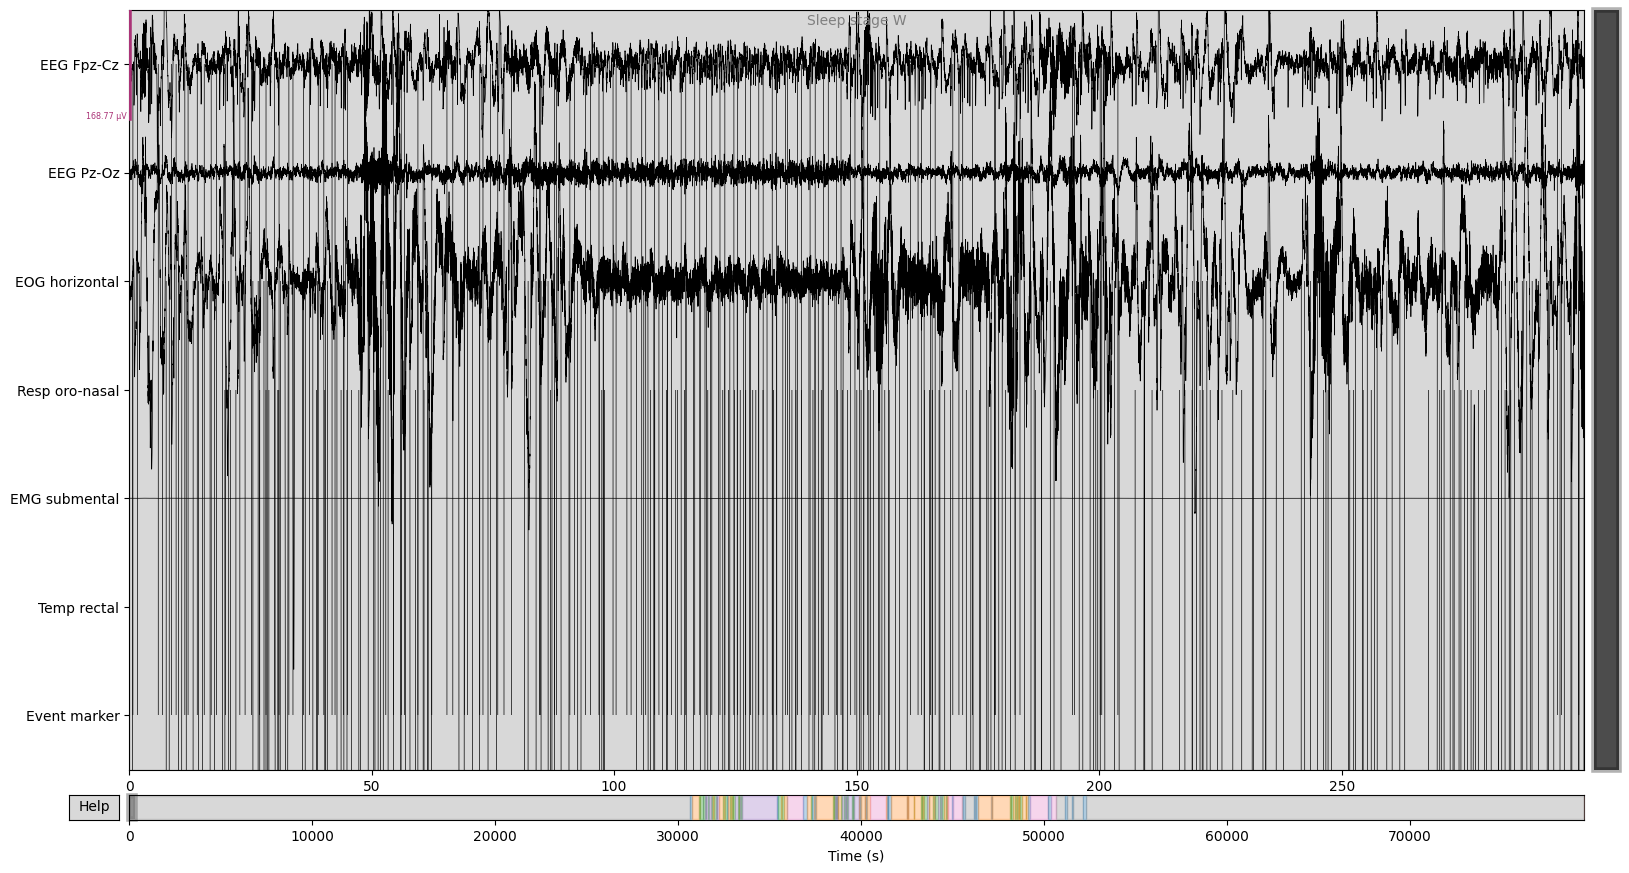

In [18]:
raw.set_annotations(annot, emit_warning=False)
fig = raw.plot(duration=300, n_channels=len(raw.ch_names), scalings='auto', show=True, block=True)

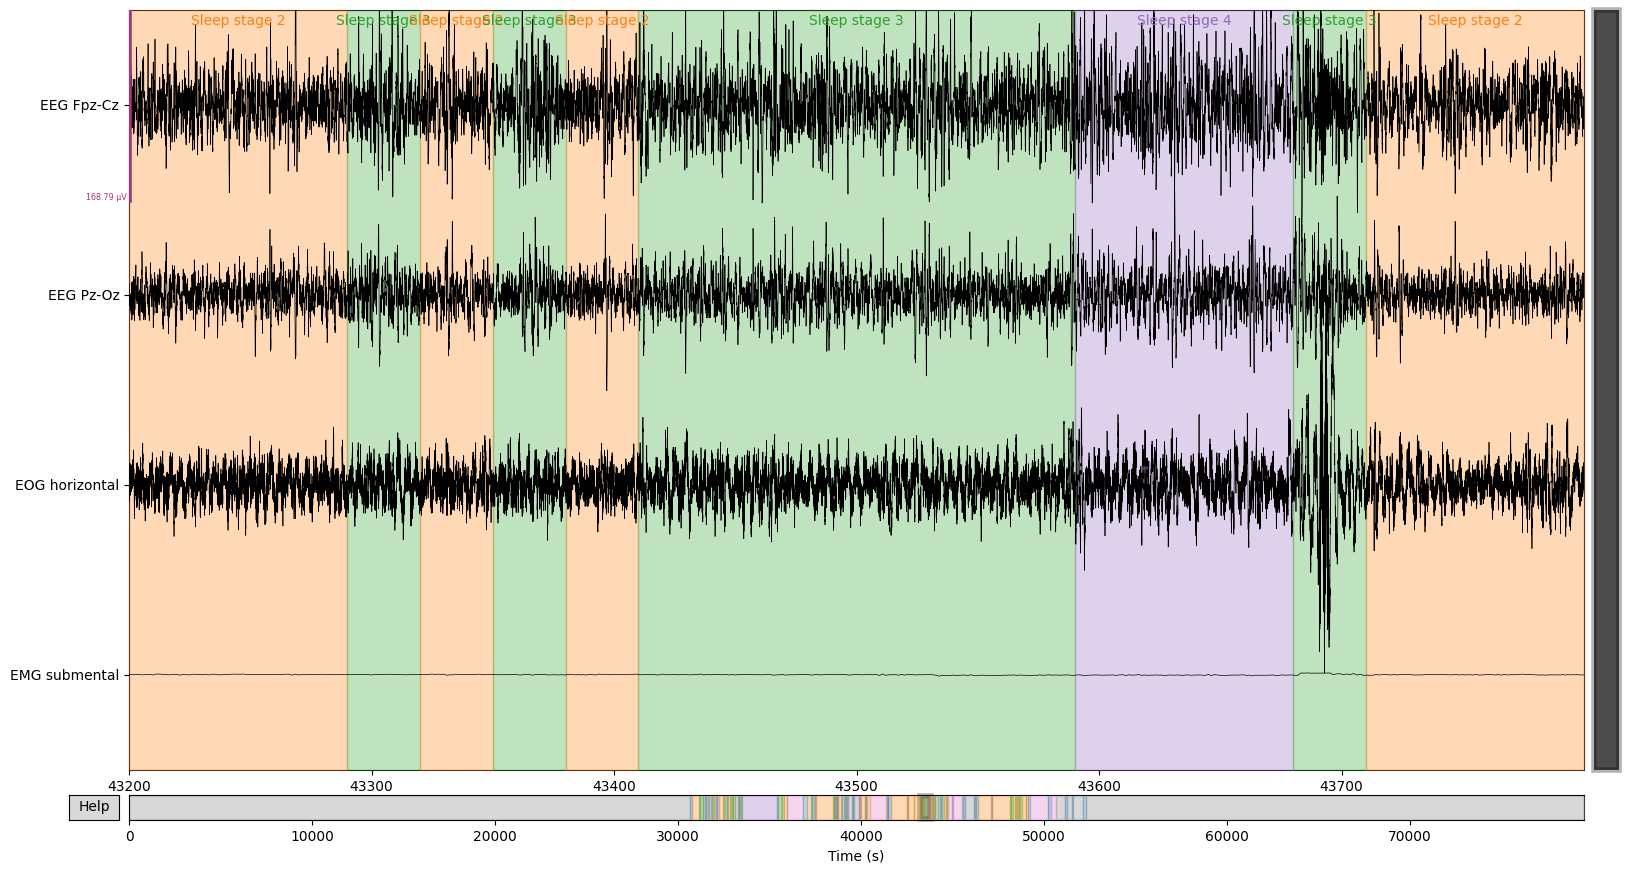

In [19]:
inicio = 720 * 60
duracion = 10 * 60

fig = raw.plot(
    start=inicio,
    duration=duracion,
    picks=channels_to_use,
    scalings="auto",
    show=False,
    block=False
)

fig.set_size_inches(16, 9)

plt.show(block=True)

Extracting EDF parameters from ../data/sleep-edfx/sleep-cassette/SC4762E0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8429999  =      0.000 ... 84299.990 secs...


/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/879498616.py:4: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_2 = mne.io.read_raw_edf(psg_path + psg_file_2, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/879498616.py:4: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_2 = mne.io.read_raw_edf(psg_path + psg_file_2, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/879498616.py:4: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_2 = mne.io.read_raw_edf(psg_path + psg_file_2, preload=True)


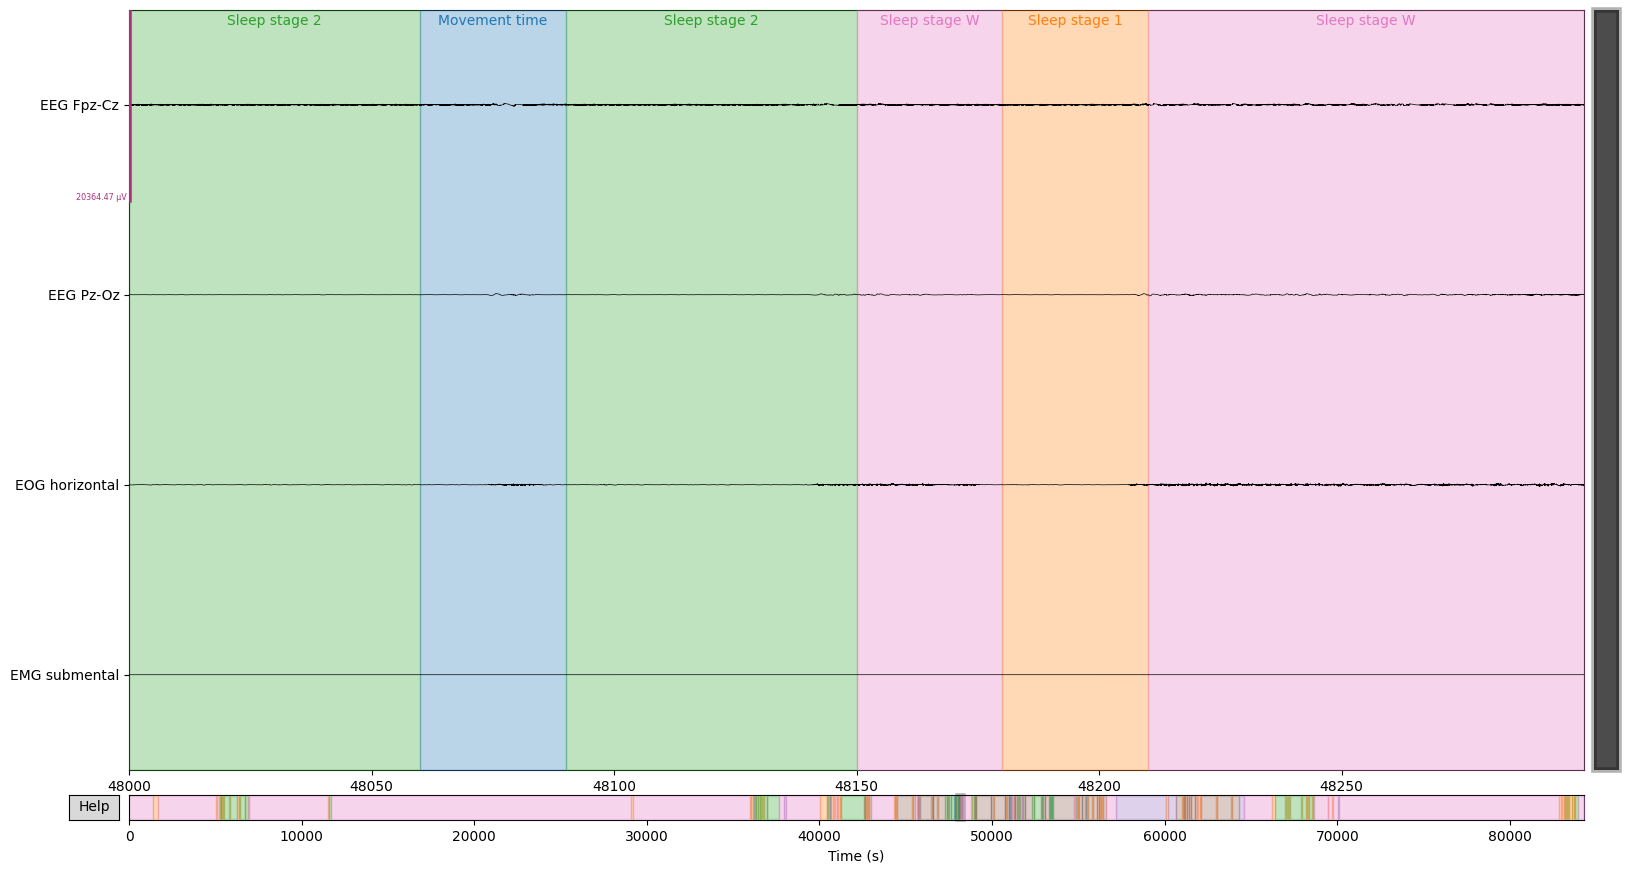

In [20]:
psg_file_2 = "SC4762E0-PSG.edf"
hypnogram_file_2 = "SC4762EG-Hypnogram.edf"

raw_2 = mne.io.read_raw_edf(psg_path + psg_file_2, preload=True)
annot_2 = mne.read_annotations(psg_path + hypnogram_file_2)
raw_2.set_annotations(annot_2, emit_warning=False)

inicio = 800 * 60
duracion = 5 * 60

fig = raw_2.plot(
    start=inicio,
    duration=duracion,
    picks=channels_to_use,
    scalings="auto",
    show=False,
    block=False
)

fig.set_size_inches(16, 9)

plt.show(block=True)

Extracting EDF parameters from ../data/sleep-edfx/sleep-cassette/SC4331F0-PSG.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 8429999  =      0.000 ... 84299.990 secs...


/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/3304942563.py:4: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_3 = mne.io.read_raw_edf(psg_path + psg_file_3, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/3304942563.py:4: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_3 = mne.io.read_raw_edf(psg_path + psg_file_3, preload=True)
/var/folders/ps/szt64w3x129_ld0z76l7m7cc0000gn/T/ipykernel_37342/3304942563.py:4: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_3 = mne.io.read_raw_edf(psg_path + psg_file_3, preload=True)


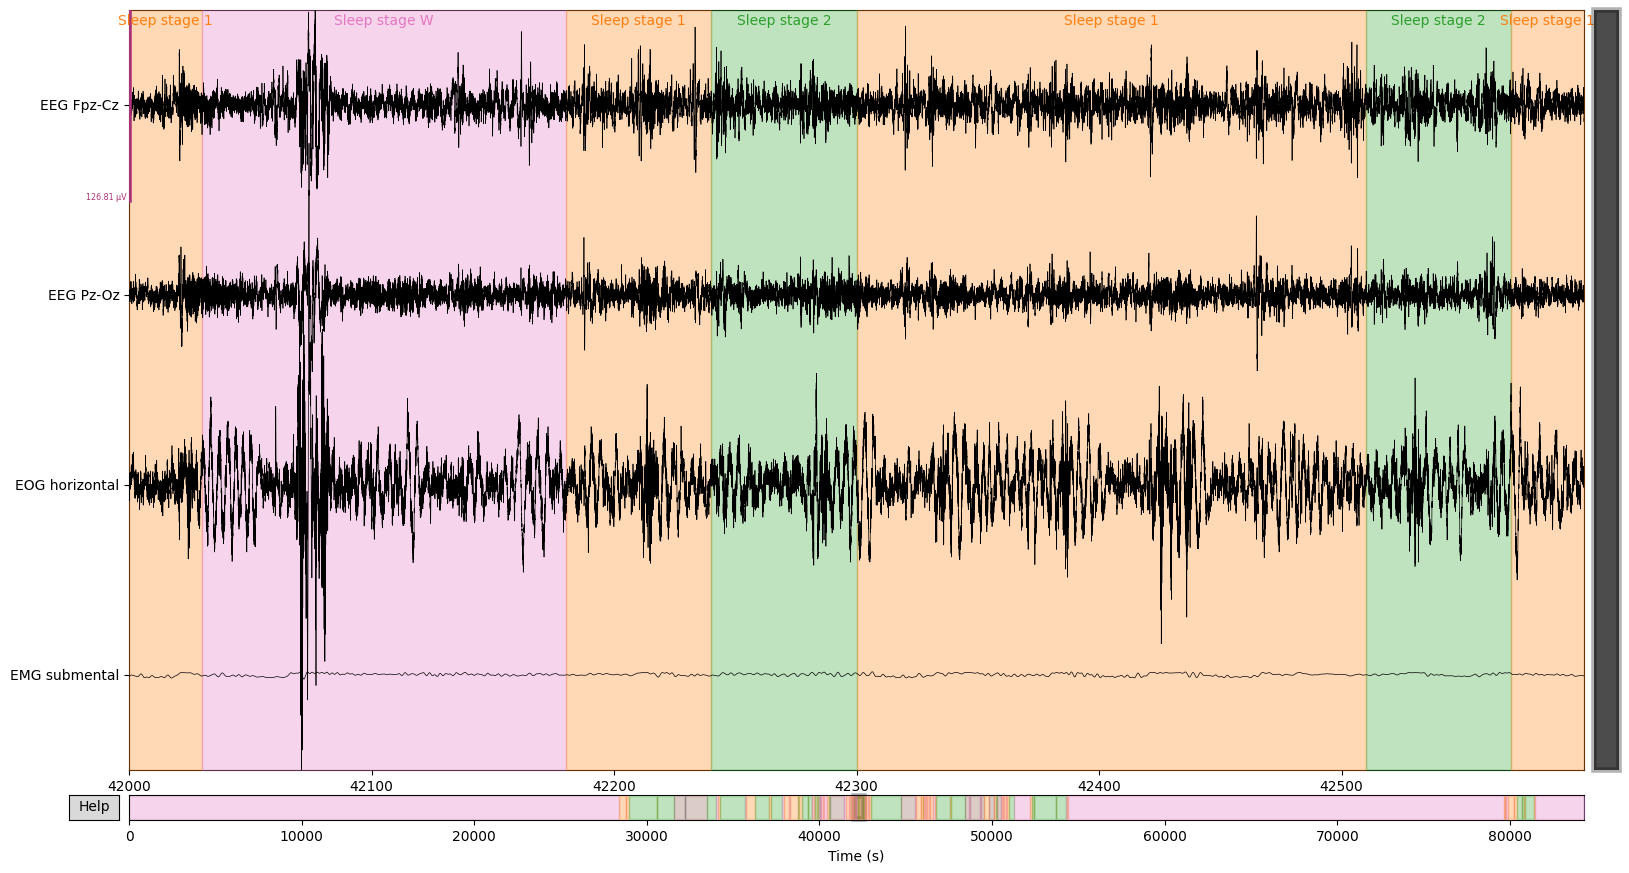

In [21]:
psg_file_3 = "SC4331F0-PSG.edf"
hypnogram_file_3 = "SC4331FV-Hypnogram.edf"

raw_3 = mne.io.read_raw_edf(psg_path + psg_file_3, preload=True)
annot_3 = mne.read_annotations(psg_path + hypnogram_file_3)
raw_3.set_annotations(annot_3, emit_warning=False)

inicio = 700 * 60
duracion = 10 * 60

fig = raw_3.plot(
    start=inicio,
    duration=duracion,
    picks=channels_to_use,
    scalings="auto",
    show=False,
    block=False
)

fig.set_size_inches(16, 9)

plt.show(block=True)

## Anotaciones de todos los Hypnogram (SC)

Se repite el análisis anterior para los 153 archivos Hypnogram de Sleep Cassette, para validar la duración de los intervalos anotados y ver su distribución por etapa.

Las etapas `Sleep stage 3` y `Sleep stage 4` se juntan en **N3**, `M` y `?` se conservan como categorías propias para analizar.

In [22]:
MAPEO_CLASES = {
    "Sleep stage W": "W",
    "Sleep stage 1": "N1",
    "Sleep stage 2": "N2",
    "Sleep stage 3": "N3",
    "Sleep stage 4": "N3",
    "Sleep stage R": "REM",
    "Movement time": "M",
    "Sleep stage ?": "?",
}

ORDEN_CLASES = ["W", "N1", "N2", "N3", "REM", "M", "?"]

In [23]:
hyp_files = sorted(f for f in os.listdir(psg_path) if f.endswith("-Hypnogram.edf"))

dfs = []
for hyp_f in hyp_files:
    try:
        annot_i = mne.read_annotations(os.path.join(psg_path, hyp_f))
    except Exception as e:
        print(f"Error en {hyp_f}: {e}")
        continue
    dfs.append(pd.DataFrame({
        "archivo": hyp_f,
        "sujeto": int(hyp_f[3:5]),
        "noche": int(hyp_f[5]),
        "anotacion": annot_i.description,
        "onset_seg": annot_i.onset,
        "duracion_seg": annot_i.duration
    }))

df_annot_sc = pd.concat(dfs, ignore_index=True)

# Se excluyen los intervalos '?' del final de cada hypnograma: solo completan el archivo hasta 24 h
ultima_anotacion_real = df_annot_sc[df_annot_sc["anotacion"] != "Sleep stage ?"].groupby("archivo")["onset_seg"].max()
es_relleno_final = df_annot_sc["onset_seg"] > df_annot_sc["archivo"].map(ultima_anotacion_real)
n_intervalos_excluidos = int(es_relleno_final.sum())
horas_excluidas = df_annot_sc.loc[es_relleno_final, "duracion_seg"].sum() / 3600
df_annot_sc = df_annot_sc[~es_relleno_final].reset_index(drop=True)

df_annot_sc["clase"] = df_annot_sc["anotacion"].map(MAPEO_CLASES)

nuevo_bloque = df_annot_sc["clase"] != df_annot_sc.groupby("archivo")["clase"].shift()

df_bloques_sc = (
    df_annot_sc.assign(bloque=nuevo_bloque.cumsum())
    .groupby("bloque")
    .agg(archivo=("archivo", "first"), sujeto=("sujeto", "first"), noche=("noche", "first"),
         clase=("clase", "first"), onset_seg=("onset_seg", "first"), duracion_seg=("duracion_seg", "sum"))
    .reset_index(drop=True)
)

In [24]:
print(f"Archivos Hypnogram procesados: {df_annot_sc['archivo'].nunique()} de {len(hyp_files)}")
print(f"Intervalos '?' del final excluidos: {n_intervalos_excluidos} ({horas_excluidas:.1f} h)")
print(f"Total de anotaciones analizadas: {len(df_annot_sc)}")
print(f"Intervalos que no son múltiplo de 30 s: {(df_annot_sc['duracion_seg'] % 30 != 0).sum()}")
print('*----'*20)

display(df_bloques_sc.head(5))
print('*----'*20)
display(df_bloques_sc.groupby("clase")["duracion_seg"].describe().reindex(ORDEN_CLASES).round(2))

Archivos Hypnogram procesados: 153 de 153
Intervalos '?' del final excluidos: 154 (200.6 h)
Total de anotaciones analizadas: 22276
Intervalos que no son múltiplo de 30 s: 0
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----


,archivo,sujeto,noche,clase,onset_seg,duracion_seg
0,SC4001EC-Hypnogram.edf,0,1,W,0.0,30630.0
1,SC4001EC-Hypnogram.edf,0,1,N1,30630.0,120.0
2,SC4001EC-Hypnogram.edf,0,1,N2,30750.0,390.0
3,SC4001EC-Hypnogram.edf,0,1,N3,31140.0,30.0
4,SC4001EC-Hypnogram.edf,0,1,N2,31170.0,30.0


*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----


,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
W,3698.0,2319.66,7098.25,30.0,30.0,60.0,210.0,40530.0
N1,5944.0,108.62,136.65,30.0,30.0,60.0,120.0,2040.0
N2,6378.0,325.17,463.34,30.0,60.0,120.0,390.0,5160.0
N3,2663.0,146.89,317.92,30.0,30.0,30.0,90.0,3510.0
REM,1560.0,496.83,537.12,30.0,120.0,300.0,690.0,3390.0
M,123.0,31.22,5.95,30.0,30.0,30.0,30.0,60.0
?,20.0,1464.00,5356.89,30.0,30.0,45.0,330.0,24060.0


In [25]:
(df_bloques_sc.groupby("clase")["duracion_seg"].sum().reindex(ORDEN_CLASES))/60

clase
W      142968.5
N1      10761.0
N2      34566.0
N3       6519.5
REM     12917.5
M          64.0
?         488.0
Name: duracion_seg, dtype: float64

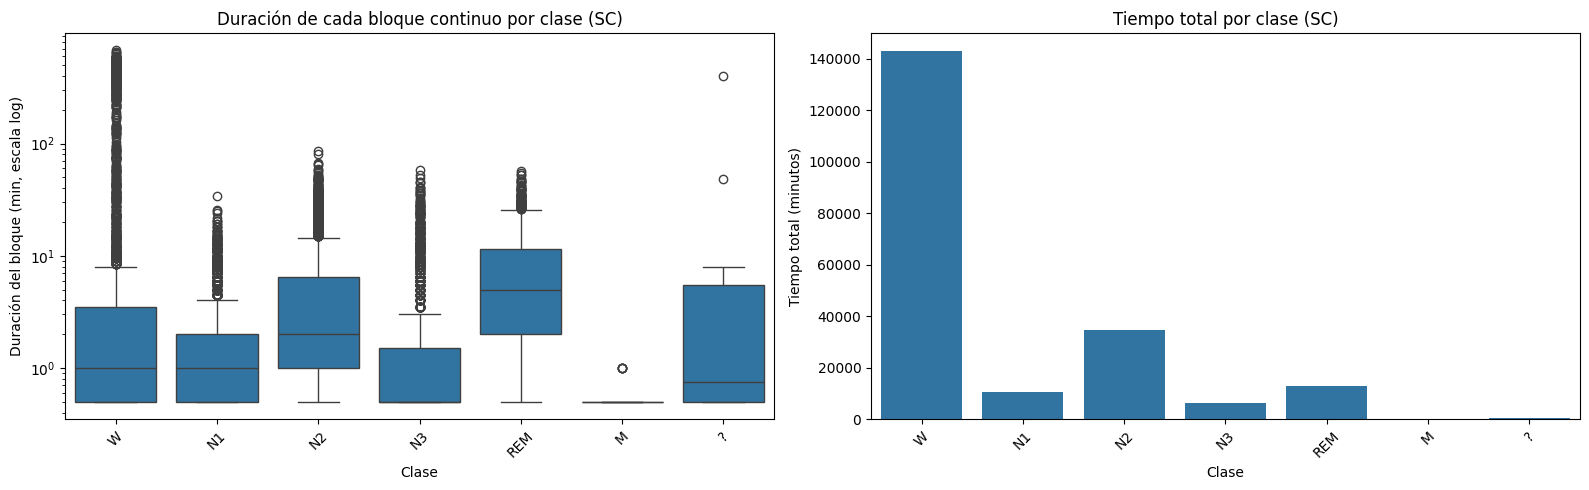

Tiempo total por clase (horas):
clase
W      2382.8
N1      179.4
N2      576.1
N3      108.7
REM     215.3
M         1.1
?         8.1
Name: duracion_min, dtype: float64


In [26]:
df_bloques_sc["duracion_min"] = df_bloques_sc["duracion_seg"] / 60
minutos_por_clase = df_bloques_sc.groupby("clase")["duracion_min"].sum().reindex(ORDEN_CLASES)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Duración de cada bloque
sns.boxplot(data=df_bloques_sc, x="clase", y="duracion_min", order=ORDEN_CLASES, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Duración del bloque (min, escala log)")
axes[0].set_title("Duración de cada bloque continuo por clase (SC)")
axes[0].tick_params(axis="x", rotation=45)

# Tiempo total acumulado por clase
sns.barplot(x=minutos_por_clase.index, y=minutos_por_clase.values, order=ORDEN_CLASES, ax=axes[1])
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Tiempo total (minutos)")
axes[1].set_title("Tiempo total por clase (SC)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print("Tiempo total por clase (horas):")
print((minutos_por_clase / 60).round(1))

## Anotaciones separadas en épocas de 30 s

Como todos los intervalos son múltiplos de 30 s, significa que al realizar las anotaciónes agruparon periodos con la misma clase en intervalos largo, por ejemplo un intervalo de 300 s equivale a 10 épocas consecutivas de 30 s con la misma etiqueta. Contar intervalos sobrerrepresenta las etapas que cambian seguido (N1, N3) y subrepresenta las que duran mucho (W), así que la distribución real de etiquetas se revisa contando **épocas de 30 s**, que es la unidad con la que se entrenará el modelo.

Esta sección usa **solo los hypnogramas** (no se leen los PSG), porque es un análisis de las anotaciones. Se parte de `df_annot_sc`, que ya excluye los intervalos `?` del final de cada archivo, así que solo se cuentan épocas que corresponden a la grabación. Las anotaciones `M` y `?` se conservan como categorías propias.

In [27]:
EPOCA_SEG = 30

CLASES_SUENO = ["N1", "N2", "N3", "REM"]

# Cada intervalo se repite tantas veces como épocas de 30 s contiene
n_epocas = (df_annot_sc["duracion_seg"] // EPOCA_SEG).astype(int)
df_epocas_sc = df_annot_sc.loc[df_annot_sc.index.repeat(n_epocas)].copy()
df_epocas_sc["inicio_seg"] = df_epocas_sc["onset_seg"] + df_epocas_sc.groupby(level=0).cumcount() * EPOCA_SEG
df_epocas_sc["clase"] = df_epocas_sc["anotacion"].map(MAPEO_CLASES)
df_epocas_sc = (
    df_epocas_sc[["archivo", "sujeto", "noche", "inicio_seg", "anotacion", "clase"]]
    .sort_values(["archivo", "inicio_seg"])
    .reset_index(drop=True)
)

# Validaciones de la expansión
saltos = df_epocas_sc.groupby("archivo")["inicio_seg"].diff().dropna()
print(f"Épocas de 30 s generadas: {len(df_epocas_sc)})")
print('*----'*20)

# Conteo por clase (MAPEO_CLASES): Sleep stage 3 y 4 cuentan juntos como N3
dist_anotaciones = pd.DataFrame({
    "n_intervalos": df_annot_sc["clase"].value_counts(),
    "n_epocas_30s": df_epocas_sc["clase"].value_counts(),
}).reindex(ORDEN_CLASES).fillna(0).astype(int)
dist_anotaciones["%_intervalos"] = (dist_anotaciones["n_intervalos"] / dist_anotaciones["n_intervalos"].sum() * 100).round(2)
dist_anotaciones["%_epocas_30s"] = (dist_anotaciones["n_epocas_30s"] / dist_anotaciones["n_epocas_30s"].sum() * 100).round(2)
display(dist_anotaciones)
print('*----'*20)

dist_clases = df_epocas_sc["clase"].value_counts().reindex(ORDEN_CLASES).fillna(0).astype(int).to_frame("n_epocas_30s")
dist_clases["%"] = (dist_clases["n_epocas_30s"] / dist_clases["n_epocas_30s"].sum() * 100).round(2)
display(dist_clases)

Épocas de 30 s generadas: 416569)
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----


,n_intervalos,n_epocas_30s,%_intervalos,%_epocas_30s
clase,,,,
W,3698,285937,16.60,68.64
N1,5944,21522,26.68,5.17
N2,6378,69132,28.63,16.60
N3,4553,13039,20.44,3.13
REM,1560,25835,7.00,6.20
M,123,128,0.55,0.03
?,20,976,0.09,0.23


*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----


,n_epocas_30s,%
clase,,
W,285937,68.64
N1,21522,5.17
N2,69132,16.60
N3,13039,3.13
REM,25835,6.20
M,128,0.03
?,976,0.23


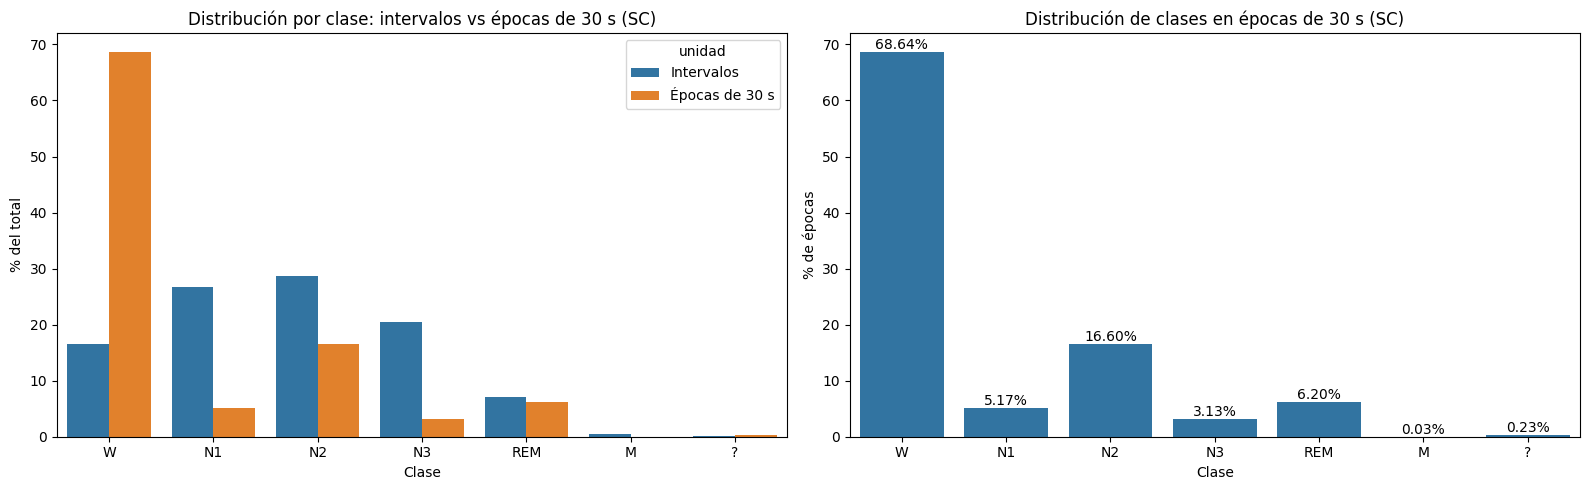

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# numero de intervalos vs numero de épocas de 30 s
dist_plot = (
    dist_anotaciones[["%_intervalos", "%_epocas_30s"]]
    .rename(columns={"%_intervalos": "Intervalos", "%_epocas_30s": "Épocas de 30 s"})
    .reset_index(names="clase")
    .melt(id_vars="clase", var_name="unidad", value_name="porcentaje")
)
sns.barplot(data=dist_plot, x="clase", y="porcentaje", hue="unidad", order=ORDEN_CLASES, ax=axes[0])
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("% del total")
axes[0].set_title("Distribución por clase: intervalos vs épocas de 30 s (SC)")

# Distribución de clases finales
sns.barplot(x=dist_clases.index, y=dist_clases["%"], ax=axes[1])
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("% de épocas")
axes[1].set_title("Distribución de clases en épocas de 30 s (SC)")
for i, pct in enumerate(dist_clases["%"]):
    axes[1].text(i, pct, f"{pct:.2f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Recorte de vigilia en los bordes

En cada grabación se conserva desde `BUFFER_EPOCAS` épocas antes de la **primera** época de sueño real (N1, N2, N3 o REM) hasta `BUFFER_EPOCAS` épocas después de la **última**. Para probar se tendra `BUFFER_EPOCAS = 60`, es decir 30 minutos de vigilia a cada lado, valor típico en la literatura de sleep staging (p. ej. DeepSleepNet). Los despertares dentro de la noche no se tocan: solo se quita la vigilia prolongada antes de dormirse y después de despertar, aunque cabe anotar que si existen siestas en algun otro momento estos afectan al recorte como por ejemplo el paciente **SC4762E0** que se grafico en la sección "Ejemplos de Hipnogramas".

In [29]:
BUFFER_EPOCAS = 60


def recortar_vigilia(df, buffer_epocas=BUFFER_EPOCAS):
    posicion = df.groupby("archivo").cumcount()
    posicion_sueno = posicion.where(df["clase"].isin(CLASES_SUENO))
    primera = posicion_sueno.groupby(df["archivo"]).transform("min")
    ultima = posicion_sueno.groupby(df["archivo"]).transform("max")
    return df[(posicion >= primera - buffer_epocas) & (posicion <= ultima + buffer_epocas)]


df_recortado = recortar_vigilia(df_epocas_sc)

print(f"Buffer: {BUFFER_EPOCAS} épocas ({BUFFER_EPOCAS * EPOCA_SEG / 60:.0f} min)")
print(f"Épocas: antes del recorte {len(df_epocas_sc)}, después del recorte {len(df_recortado)} "
      f"({(1 - len(df_recortado) / len(df_epocas_sc)) * 100:.1f}% menos)")
print('*----'*20)

# Distribución de clases antes y después del recorte
dist_recorte = pd.DataFrame({
    "n_antes": df_epocas_sc["clase"].value_counts(),
    "n_despues": df_recortado["clase"].value_counts(),
}).reindex(ORDEN_CLASES).fillna(0).astype(int)
dist_recorte["%_antes"] = (dist_recorte["n_antes"] / dist_recorte["n_antes"].sum() * 100).round(2)
dist_recorte["%_despues"] = (dist_recorte["n_despues"] / dist_recorte["n_despues"].sum() * 100).round(2)
dist_recorte["%_conservado"] = (dist_recorte["n_despues"] / dist_recorte["n_antes"] * 100).round(1)
print("Distribución de clases antes y después del recorte:")
display(dist_recorte)

Buffer: 60 épocas (30 min)
Épocas: antes del recorte 416569, después del recorte 195766 (53.0% menos)
*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----*----
Distribución de clases antes y después del recorte:


,n_antes,n_despues,%_antes,%_despues,%_conservado
clase,,,,,
W,285937,65941,68.64,33.68,23.1
N1,21522,21522,5.17,10.99,100.0
N2,69132,69132,16.60,35.31,100.0
N3,13039,13039,3.13,6.66,100.0
REM,25835,25835,6.20,13.20,100.0
M,128,128,0.03,0.07,100.0
?,976,169,0.23,0.09,17.3


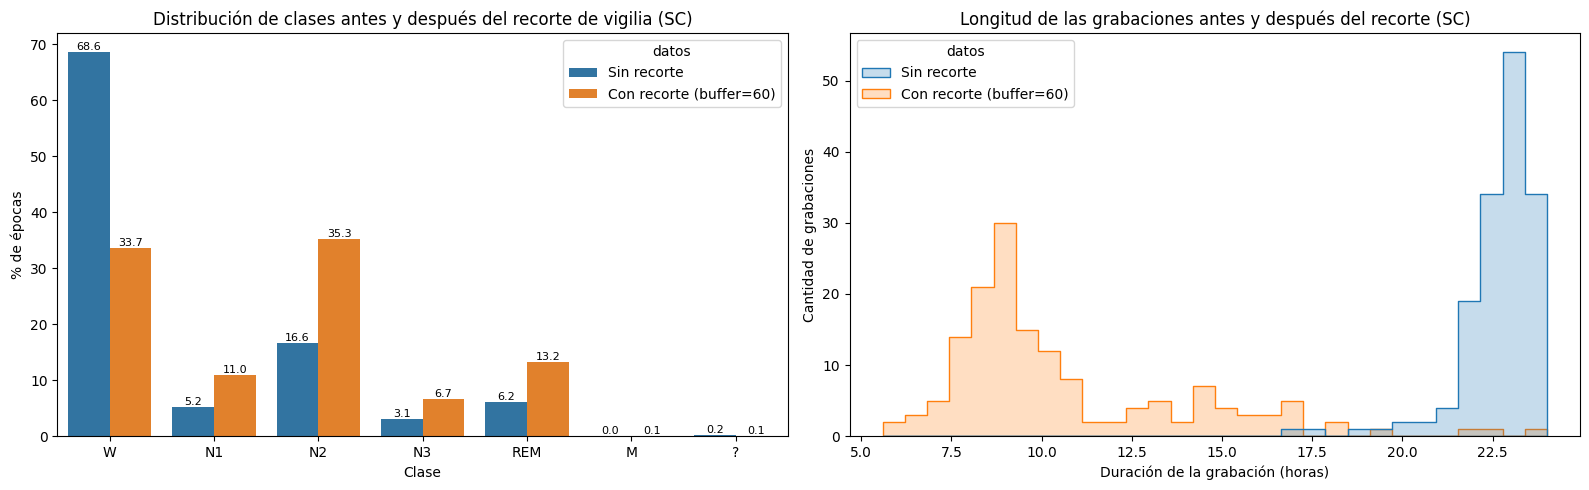

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# % por clase antes y después del recorte
dist_recorte_plot = (
    dist_recorte[["%_antes", "%_despues"]]
    .rename(columns={"%_antes": "Sin recorte", "%_despues": f"Con recorte (buffer={BUFFER_EPOCAS})"})
    .reset_index(names="clase")
    .melt(id_vars="clase", var_name="datos", value_name="porcentaje")
)
sns.barplot(data=dist_recorte_plot, x="clase", y="porcentaje", hue="datos", ax=axes[0])
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("% de épocas")
axes[0].set_title("Distribución de clases antes y después del recorte de vigilia (SC)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f", fontsize=8)

# Longitud de cada grabación antes y después del recorte
longitudes = pd.DataFrame({
    "epocas_antes": df_epocas_sc.groupby("archivo").size(),
    "epocas_despues": df_recortado.groupby("archivo").size(),
})
longitudes["horas_antes"] = longitudes["epocas_antes"] * EPOCA_SEG / 3600
longitudes["horas_despues"] = longitudes["epocas_despues"] * EPOCA_SEG / 3600

longitudes_plot = longitudes[["horas_antes", "horas_despues"]].rename(
    columns={"horas_antes": "Sin recorte", "horas_despues": f"Con recorte (buffer={BUFFER_EPOCAS})"}
).melt(var_name="datos", value_name="horas")
sns.histplot(data=longitudes_plot, x="horas", hue="datos", bins=30, element="step", ax=axes[1])
axes[1].set_xlabel("Duración de la grabación (horas)")
axes[1].set_ylabel("Cantidad de grabaciones")
axes[1].set_title("Longitud de las grabaciones antes y después del recorte (SC)")

plt.tight_layout()
plt.show()

## Ejemplo: señales antes y después del recorte

Para una grabación se grafican los canales EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal y EMG submental, **antes** (grabación completa) y **después** del recorte de vigilia con `BUFFER_EPOCAS`. En la columna "antes" el tramo sombreado es lo que conserva el recorte.

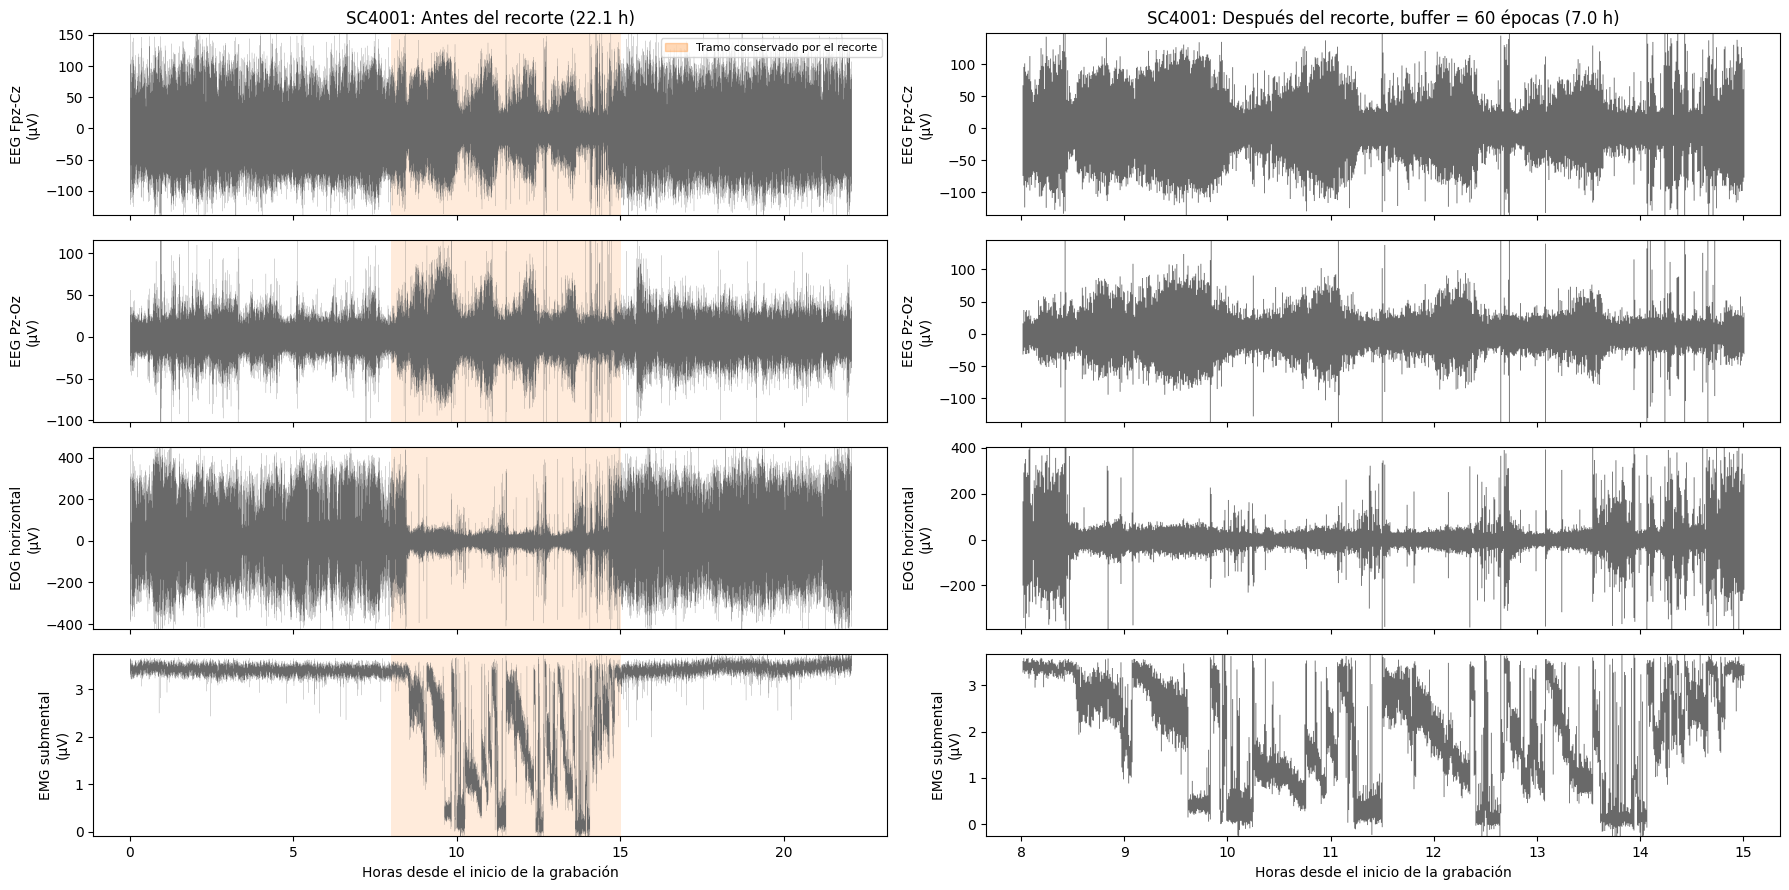

Tramo conservado: 8.01 h a 15.02 h


In [31]:
CANALES_FIGURA = ["EEG Fpz-Cz", "EEG Pz-Oz", "EOG horizontal", "EMG submental"]


def graficar_recorte(hyp_ejemplo, psg_ejemplo):
    grabacion = hyp_ejemplo[:6]

    # Señal: rango (mín, máx) de cada época de 30 s, en µV
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # avisos de filtros del EDF
        raw_ejemplo = mne.io.read_raw_edf(os.path.join(psg_path, psg_ejemplo), include=CANALES_FIGURA, preload=True, verbose=False)
    senal = raw_ejemplo.get_data(picks=CANALES_FIGURA, units="uV")
    muestras_epoca = int(EPOCA_SEG * raw_ejemplo.info["sfreq"])
    n_epocas_senal = senal.shape[1] // muestras_epoca
    senal_epocas = senal[:, :n_epocas_senal * muestras_epoca].reshape(len(CANALES_FIGURA), n_epocas_senal, muestras_epoca)
    senal_min, senal_max = senal_epocas.min(axis=2), senal_epocas.max(axis=2)
    horas_senal = np.arange(n_epocas_senal) * EPOCA_SEG / 3600

    # Tramo que conserva el recorte, según las anotaciones
    hip_antes = df_epocas_sc[df_epocas_sc["archivo"] == hyp_ejemplo]
    hip_despues = df_recortado[df_recortado["archivo"] == hyp_ejemplo]
    inicio_recorte = hip_despues["inicio_seg"].min() / 3600
    fin_recorte = (hip_despues["inicio_seg"].max() + EPOCA_SEG) / 3600
    en_recorte = (horas_senal >= inicio_recorte) & (horas_senal < fin_recorte)

    fig, axes = plt.subplots(len(CANALES_FIGURA), 2, figsize=(18, 9), sharex="col")
    columnas = [
        (np.ones_like(en_recorte), f"Antes del recorte ({len(hip_antes) * EPOCA_SEG / 3600:.1f} h)"),
        (en_recorte, f"Después del recorte, buffer = {BUFFER_EPOCAS} épocas ({len(hip_despues) * EPOCA_SEG / 3600:.1f} h)"),
    ]

    for col, (mascara, titulo) in enumerate(columnas):
        axes[0, col].set_title(f"{grabacion}: {titulo}")

        for fila, canal in enumerate(CANALES_FIGURA):
            ax = axes[fila, col]
            ax.fill_between(horas_senal[mascara], senal_min[fila][mascara], senal_max[fila][mascara],
                            step="post", color="dimgray", linewidth=0)
            ax.set_ylim(np.percentile(senal_min[fila][mascara], 1), np.percentile(senal_max[fila][mascara], 99))
            ax.set_ylabel(f"{canal}\n(µV)")

        axes[-1, col].set_xlabel("Horas desde el inicio de la grabación")

    # Tramo que conserva el recorte
    for ax in axes[:, 0]:
        ax.axvspan(inicio_recorte, fin_recorte, color="tab:orange", alpha=0.15, linewidth=0, zorder=0)
    axes[0, 0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:orange", alpha=0.3)],
                      labels=["Tramo conservado por el recorte"], loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()

    print(f"Tramo conservado: {inicio_recorte:.2f} h a {fin_recorte:.2f} h")


graficar_recorte("SC4001EC-Hypnogram.edf", "SC4001E0-PSG.edf")

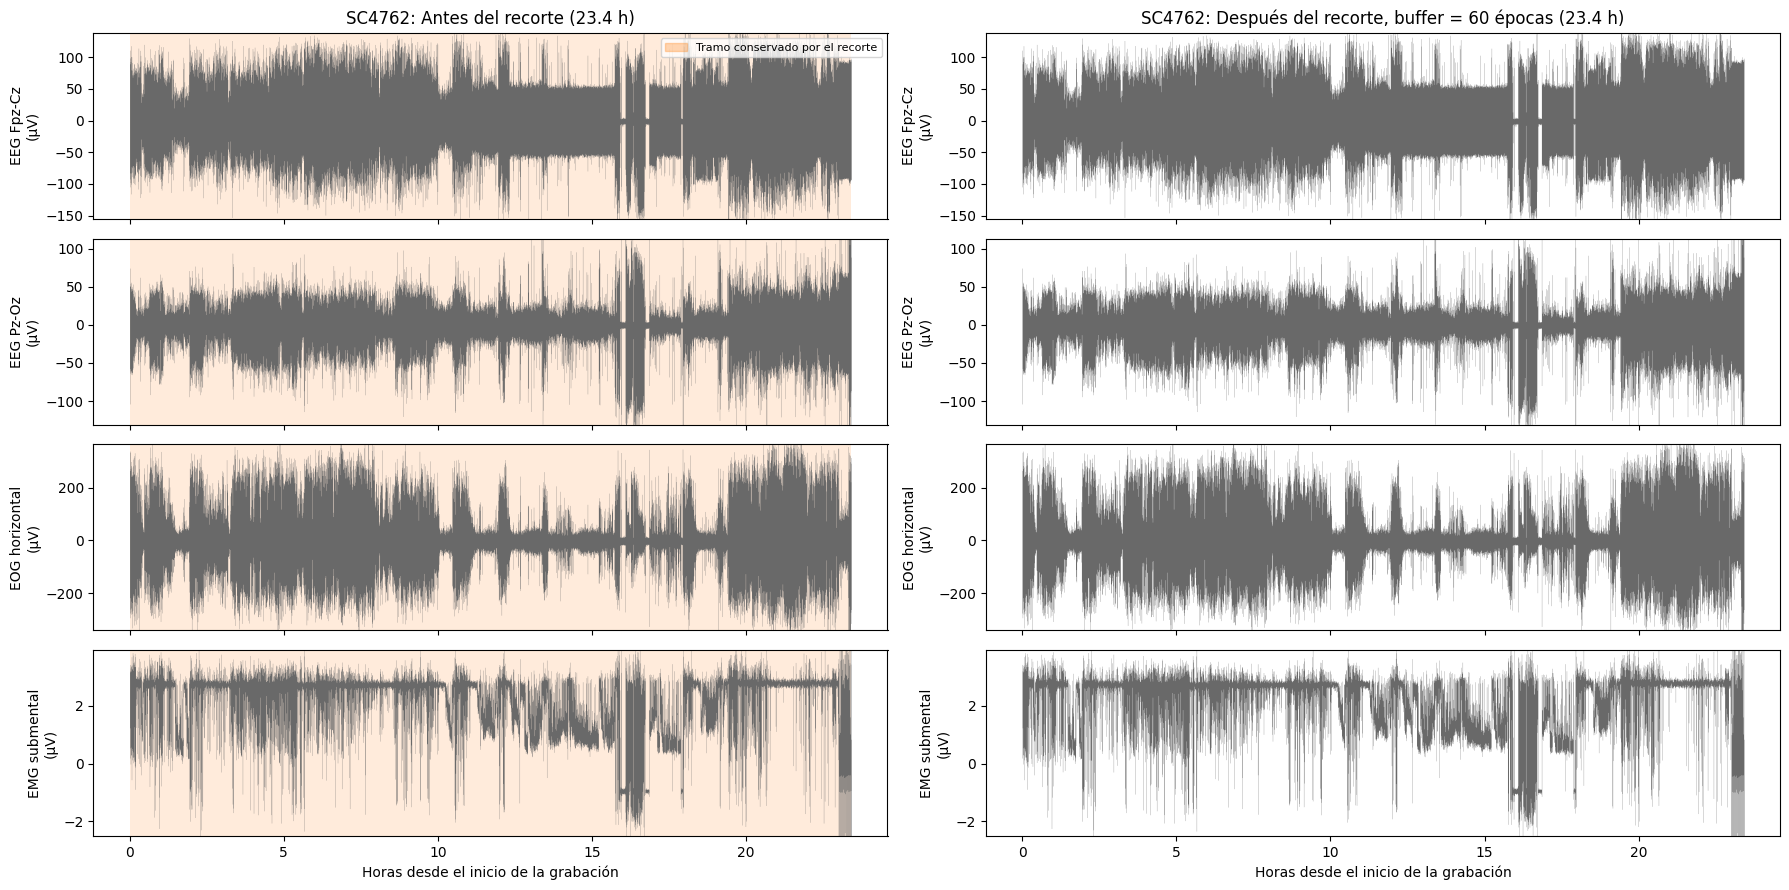

Tramo conservado: 0.00 h a 23.42 h


In [32]:
psg_file_2 = "SC4762E0-PSG.edf"
hypnogram_file_2 = "SC4762EG-Hypnogram.edf"

graficar_recorte(hypnogram_file_2, psg_file_2)

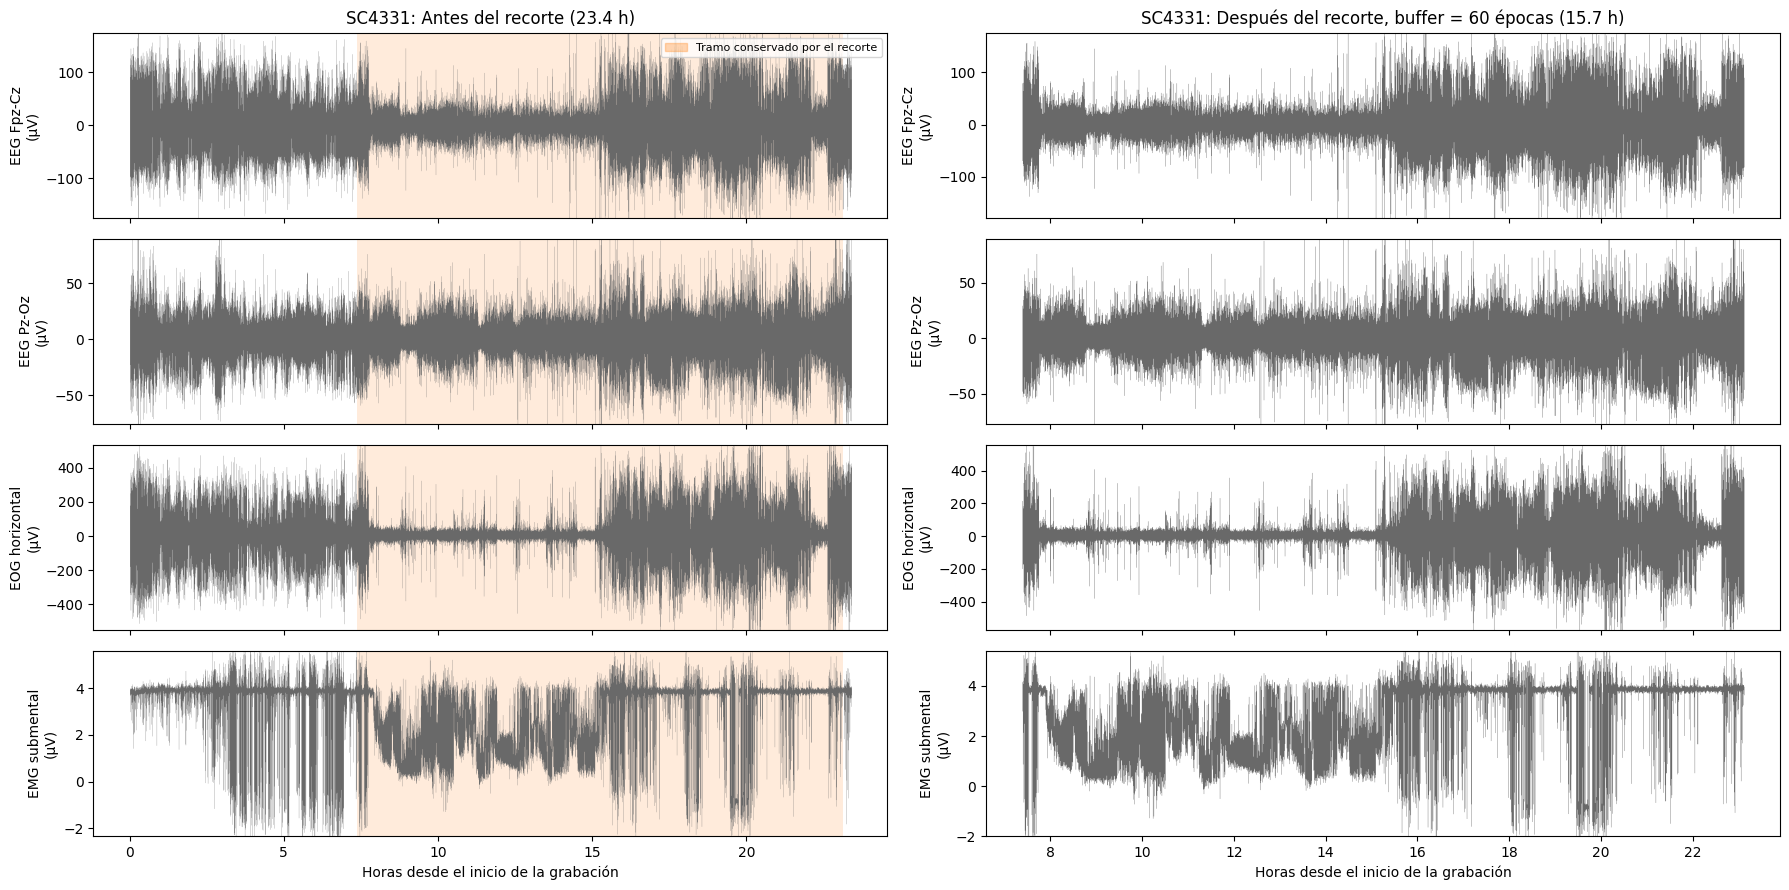

Tramo conservado: 7.38 h a 23.12 h


In [33]:
graficar_recorte(hypnogram_file_3, psg_file_3)